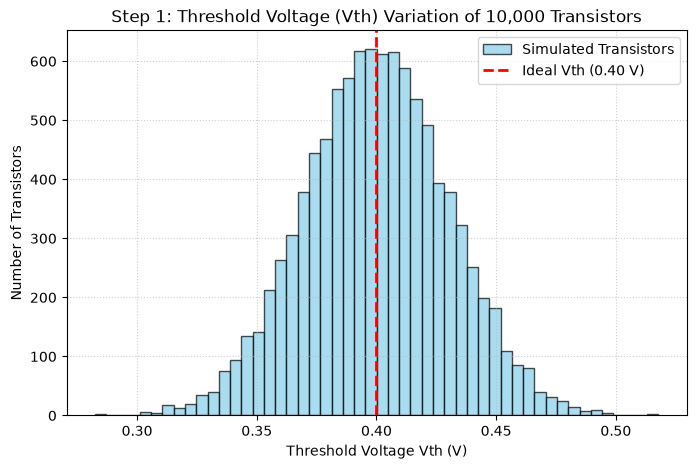

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Set random seed for reproducibility across simulations
np.random.seed(42)

# 2. Define nominal transistor parameters (Mean Vth = 0.40V, Pelgrom sigma = 30mV)
vth_nominal = 0.40
vth_sigma = 0.03
num_samples = 10000

# 3. Monte Carlo sampling: generate 10,000 Gaussian-distributed Vth values
vth_samples = np.random.normal(loc=vth_nominal, scale=vth_sigma, size=num_samples)

# 4. Plot the threshold voltage distribution histogram
plt.figure(figsize=(8, 5))
plt.hist(vth_samples, bins=50, color='skyblue', edgecolor='black', alpha=0.7, label='Simulated Transistors')
plt.axvline(vth_nominal, color='red', linestyle='--', linewidth=2, label='Ideal Vth (0.40 V)')

plt.title('Step 1: Threshold Voltage (Vth) Variation of 10,000 Transistors')
plt.xlabel('Threshold Voltage Vth (V)')
plt.ylabel('Number of Transistors')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# 5. Export high-resolution figure and display plot
plt.savefig('figures/step1_vth_hist.png', dpi=300, bbox_inches='tight')
plt.show()

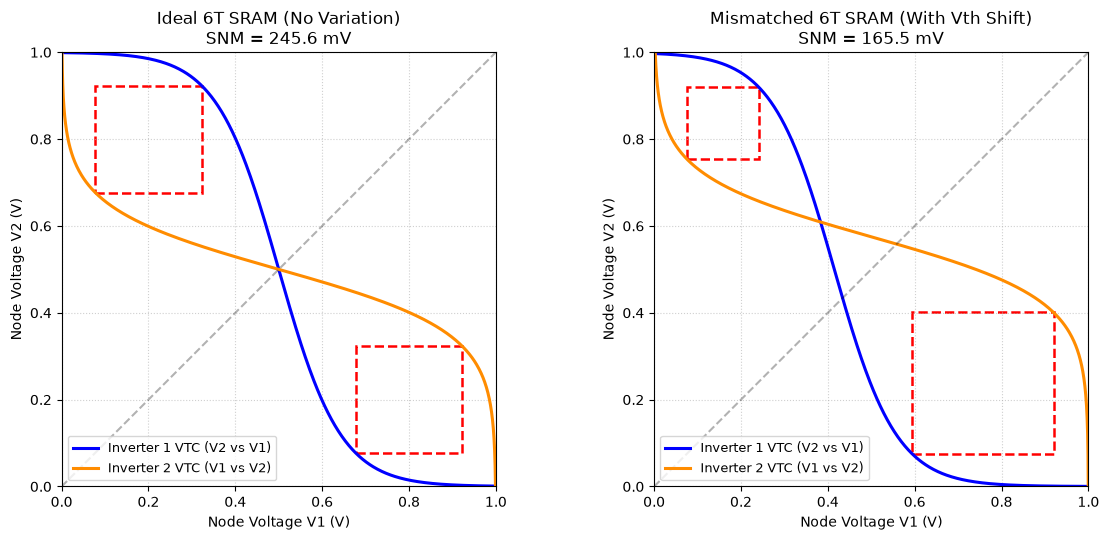

In [12]:
# Step 2: 6T SRAM Cross-Coupled Inverter Modeling, Butterfly Curve & SNM Extraction

def inverter_vtc(v_in, vdd=1.0, vth_n=0.40, vth_p=0.40, gain=14.0):
    """
    Compute the Voltage Transfer Characteristic (VTC) of a CMOS inverter.
    """
    # Calculate inverter switching threshold voltage (V_M) shifted by Vth mismatch
    v_m = (vdd - vth_p + vth_n) / 2.0
    # Behavioral sigmoid VTC transition model
    v_out = vdd / (1.0 + np.exp(gain * (v_in - v_m)))
    return v_out

def calculate_snm(vdd=1.0, vth_n1=0.40, vth_p1=0.40, vth_n2=0.40, vth_p2=0.40):
    """
    Extract the Static Noise Margin (SNM) by finding the maximum inscribed square
    inside both lobes of the 6T SRAM butterfly curve via 45-degree diagonal projection.
    """
    # 1. Generate uniform voltage sweep grid from 0V to Vdd
    v = np.linspace(0, vdd, 500)

    # 2. Compute forward VTC (Inverter 1) and mirrored VTC (Inverter 2)
    v2_inv1 = inverter_vtc(v, vdd, vth_n1, vth_p1)
    v1_inv2 = inverter_vtc(v, vdd, vth_n2, vth_p2)

    # 3. Project curves onto the 45-degree diagonal coordinate c = V2 - V1
    c_grid = np.linspace(-vdd, vdd, 500)
    # Reverse decreasing sequence [::-1] to satisfy np.interp monotonic requirement
    x_curve1 = np.interp(c_grid, (v2_inv1 - v)[::-1], v[::-1])
    x_curve2 = np.interp(c_grid, v - v1_inv2, v1_inv2)

    # 4. Separate top-left eye (c > 0) and bottom-right eye (c < 0)
    top_mask = c_grid > 0
    bot_mask = c_grid < 0

    # 5. Determine the side length of the largest inscribed square in each eye
    diff_top = x_curve1[top_mask] - x_curve2[top_mask]
    diff_bot = x_curve2[bot_mask] - x_curve1[bot_mask]

    snm_top = np.max(diff_top)
    snm_bot = np.max(diff_bot)
    snm = min(snm_top, snm_bot)  # Cell SNM is limited by the weaker lobe

    # 6. Record bottom-left vertex coordinates (x0, y0) for plotting inscribed squares
    idx_top = np.argmax(diff_top)
    c_top = c_grid[top_mask][idx_top]
    x_top_bl = x_curve2[top_mask][idx_top]

    idx_bot = np.argmax(diff_bot)
    c_bot = c_grid[bot_mask][idx_bot]
    x_bot_bl = x_curve1[bot_mask][idx_bot]

    info = {
        'v': v, 'v2_inv1': v2_inv1, 'v1_inv2': v1_inv2,
        'top_sq': (x_top_bl, x_top_bl + c_top, snm_top),
        'bot_sq': (x_bot_bl, x_bot_bl + c_bot, snm_bot)
    }
    return snm, info

# Evaluate nominal bitcell vs. process-mismatched bitcell
snm_ideal, info_ideal = calculate_snm(vdd=1.0, vth_n1=0.40, vth_p1=0.40, vth_n2=0.40, vth_p2=0.40)
snm_skew, info_skew   = calculate_snm(vdd=1.0, vth_n1=0.31, vth_p1=0.48, vth_n2=0.47, vth_p2=0.32)

# Plot side-by-side comparison of Butterfly Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, info, title, snm_val in zip(
    axes,
    [info_ideal, info_skew],
    ['Ideal 6T SRAM (No Variation)', 'Mismatched 6T SRAM (With Vth Shift)'],
    [snm_ideal, snm_skew]
):
    ax.plot(info['v'], info['v2_inv1'], 'b-', linewidth=2.2, label='Inverter 1 VTC (V2 vs V1)')
    ax.plot(info['v1_inv2'], info['v'], 'darkorange', linewidth=2.2, label='Inverter 2 VTC (V1 vs V2)')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)

    # Draw maximum inscribed SNM squares
    for (x0, y0, s) in [info['top_sq'], info['bot_sq']]:
        if s > 0:
            rect = plt.Rectangle((x0, y0), s, s, fill=False, edgecolor='red', linewidth=1.8, linestyle='--')
            ax.add_patch(rect)

    ax.set_title(f"{title}\nSNM = {snm_val*1000:.1f} mV")
    ax.set_xlabel('Node Voltage V1 (V)')
    ax.set_ylabel('Node Voltage V2 (V)')
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0, 1.0)
    ax.set_aspect('equal')
    ax.legend(loc='lower left', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figures/step2_butterfly.png', dpi=300, bbox_inches='tight')
plt.show()

Total Simulated Cells : 10000 6T SRAM bitcells
Mean SNM              : 229.1 mV | Std Dev: 12.1 mV
Failed Cells (<180mV) : 8 cells (Failure Rate: 0.08%)


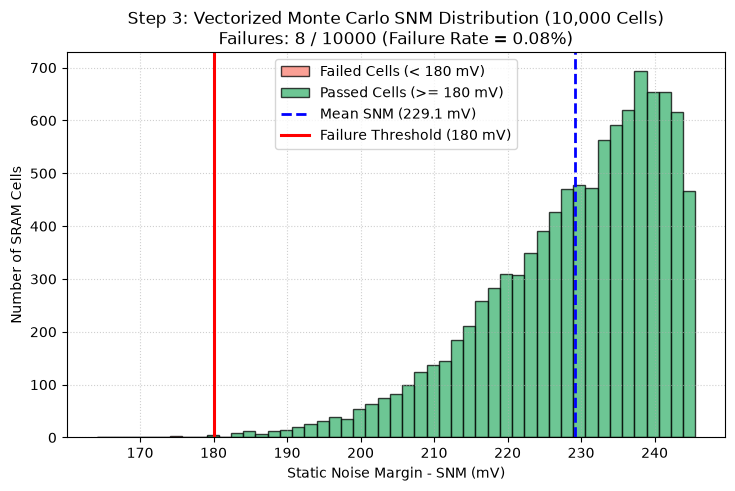

In [13]:
# Step 3: Fully Vectorized 2D NumPy Monte Carlo Simulation of 10,000 6T SRAM Cells

np.random.seed(42)

# 1. Configure Monte Carlo simulation parameters
num_cells = 10000
vdd = 1.0
vth_mean = 0.40
vth_sigma = 0.04

# 2. Generate independent Gaussian Vth column vectors of shape (10000, 1)
vth_n1 = np.random.normal(vth_mean, vth_sigma, size=(num_cells, 1))
vth_p1 = np.random.normal(vth_mean, vth_sigma, size=(num_cells, 1))
vth_n2 = np.random.normal(vth_mean, vth_sigma, size=(num_cells, 1))
vth_p2 = np.random.normal(vth_mean, vth_sigma, size=(num_cells, 1))

# 3. Compute switching thresholds for all 10,000 cells simultaneously, shape: (10000, 1)
v_m1 = (vdd - vth_p1 + vth_n1) / 2.0
v_m2 = (vdd - vth_p2 + vth_n2) / 2.0

# 4. Prepare base VTC curve and 45-degree diagonal sweep vectors of shape (1, 250)
u = np.linspace(-1.0, 1.0, 500)
v_base = vdd / (1.0 + np.exp(14.0 * u))

c_top = np.linspace(0.0, vdd, 250).reshape(1, 250)   # Top-left lobe sweep grid
c_bot = np.linspace(-vdd, 0.0, 250).reshape(1, 250)  # Bottom-right lobe sweep grid

# 5. Apply 2D NumPy broadcasting: (10000, 1) + (1, 250) -> (10000, 250) matrix
x1_top = np.clip(np.interp(c_top + v_m1, (v_base - u)[::-1], u[::-1]) + v_m1, 0.0, vdd)
x2_top = np.interp(c_top - v_m2, u - v_base, v_base)

x1_bot = np.clip(np.interp(c_bot + v_m1, (v_base - u)[::-1], u[::-1]) + v_m1, 0.0, vdd)
x2_bot = np.interp(c_bot - v_m2, u - v_base, v_base)

# 6. Extract maximum square side length along axis=1 and take element-wise minimum across lobes
snm_top = np.max(x1_top - x2_top, axis=1)
snm_bot = np.max(x2_bot - x1_bot, axis=1)
snm_array = np.minimum(snm_top, snm_bot) * 1000.0  # Convert V to mV

# 7. Partition failed and passed cells using NumPy boolean masking
fail_threshold = 180.0
fail_snm = snm_array[snm_array < fail_threshold]
pass_snm = snm_array[snm_array >= fail_threshold]

snm_mean = np.mean(snm_array)
snm_std = np.std(snm_array)
num_failures = fail_snm.size
fail_rate = (num_failures / num_cells) * 100.0

print(f"Total Simulated Cells : {num_cells} 6T SRAM bitcells")
print(f"Mean SNM              : {snm_mean:.1f} mV | Std Dev: {snm_std:.1f} mV")
print(f"Failed Cells (<180mV) : {num_failures} cells (Failure Rate: {fail_rate:.2f}%)")

# 8. Plot Monte Carlo SNM distribution histogram
plt.figure(figsize=(8.5, 5))
bins = np.linspace(np.min(snm_array), np.max(snm_array), 50)
plt.hist(fail_snm, bins=bins, color='salmon', edgecolor='black', alpha=0.75, label='Failed Cells (< 180 mV)')
plt.hist(pass_snm, bins=bins, color='mediumseagreen', edgecolor='black', alpha=0.75, label='Passed Cells (>= 180 mV)')

plt.axvline(snm_mean, color='blue', linestyle='--', linewidth=2, label=f'Mean SNM ({snm_mean:.1f} mV)')
plt.axvline(fail_threshold, color='red', linestyle='-', linewidth=2.2, label=f'Failure Threshold ({fail_threshold:.0f} mV)')

plt.title(f'Step 3: Vectorized Monte Carlo SNM Distribution (10,000 Cells)\nFailures: {num_failures} / {num_cells} (Failure Rate = {fail_rate:.2f}%)')
plt.xlabel('Static Noise Margin - SNM (mV)')
plt.ylabel('Number of SRAM Cells')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.savefig('figures/step3_mc_snm_dist.png', dpi=300, bbox_inches='tight')
plt.show()

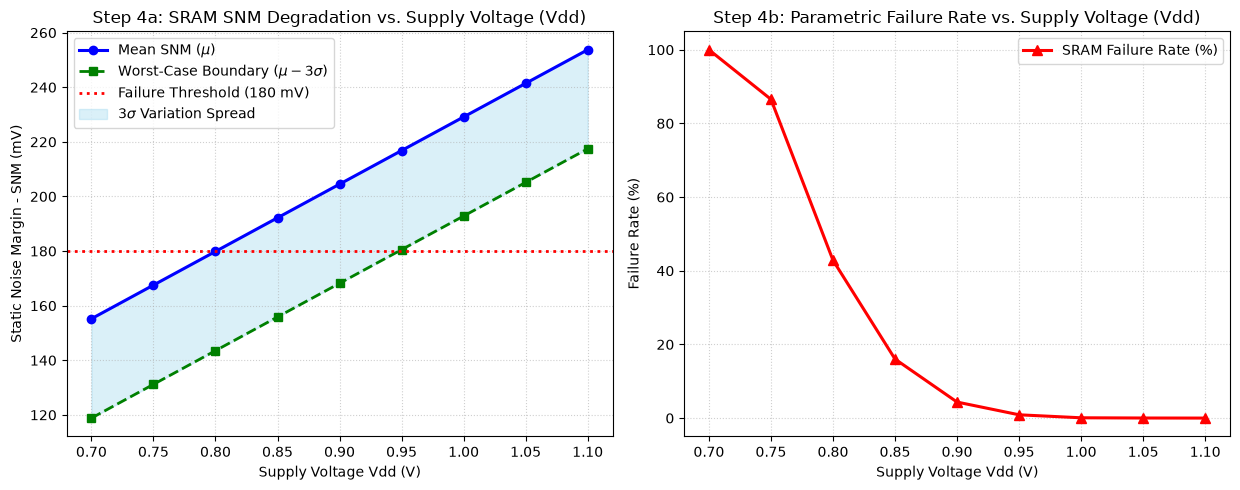

In [14]:
# Step 4: 3D Vectorized NumPy Analysis of Supply Voltage (Vdd) Scaling on SRAM Yield

# 1. Define 9 supply voltage levels from 0.70V to 1.10V along axis 0, shape: (9, 1, 1)
vdd_values = np.linspace(0.70, 1.10, 9)
vdd_3d = vdd_values.reshape(9, 1, 1)

# 2. Reshape the 10,000 transistor Vth samples along axis 1, shape: (1, 10000, 1)
vth_n1_3d = vth_n1.reshape(1, num_cells, 1)
vth_p1_3d = vth_p1.reshape(1, num_cells, 1)
vth_n2_3d = vth_n2.reshape(1, num_cells, 1)
vth_p2_3d = vth_p2.reshape(1, num_cells, 1)

# 3. Compute normalized switching thresholds via 3D broadcasting, shape: (9, 10000, 1)
vm1_norm = ((vdd_3d - vth_p1_3d + vth_n1_3d) / 2.0) / vdd_3d
vm2_norm = ((vdd_3d - vth_p2_3d + vth_n2_3d) / 2.0) / vdd_3d

# 4. Define diagonal sweep grids along axis 2, shape: (1, 1, 200)
c_top_3d = np.linspace(0.0, 1.0, 200).reshape(1, 1, 200)
c_bot_3d = np.linspace(-1.0, 0.0, 200).reshape(1, 1, 200)

# 5. Execute 3D broadcasting to evaluate (9, 10000, 200) = 90,000 SRAM states simultaneously
x1_top_3d = np.clip(np.interp(c_top_3d + vm1_norm, (v_base - u)[::-1], u[::-1]) + vm1_norm, 0.0, 1.0)
x2_top_3d = np.interp(c_top_3d - vm2_norm, u - v_base, v_base)

x1_bot_3d = np.clip(np.interp(c_bot_3d + vm1_norm, (v_base - u)[::-1], u[::-1]) + vm1_norm, 0.0, 1.0)
x2_bot_3d = np.interp(c_bot_3d - vm2_norm, u - v_base, v_base)

# 6. Extract maximum square side length along axis=2 and scale by Vdd to obtain SNM in mV
snm_top_2d = np.max(x1_top_3d - x2_top_3d, axis=2)
snm_bot_2d = np.max(x2_bot_3d - x1_bot_3d, axis=2)
snm_matrix = np.minimum(snm_top_2d, snm_bot_2d) * vdd_values.reshape(9, 1) * 1000.0  # Shape: (9, 10000)

# 7. Compute statistical metrics (Mean, 3-Sigma worst-case boundary, and Failure Rate) along axis=1
mean_snm_per_vdd = np.mean(snm_matrix, axis=1)
std_snm_per_vdd = np.std(snm_matrix, axis=1)
worst_3sigma_snm = mean_snm_per_vdd - 3.0 * std_snm_per_vdd
fail_rate_per_vdd = np.mean(snm_matrix < fail_threshold, axis=1) * 100.0

# 8. Plot SNM degradation and parametric failure rate across Vdd scaling
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5))

ax1.plot(vdd_values, mean_snm_per_vdd, 'b-o', linewidth=2.2, label=r'Mean SNM ($\mu$)')
ax1.plot(vdd_values, worst_3sigma_snm, 'g--s', linewidth=2, label=r'Worst-Case Boundary ($\mu - 3\sigma$)')
ax1.axhline(fail_threshold, color='red', linestyle=':', linewidth=2, label=f'Failure Threshold ({fail_threshold:.0f} mV)')
ax1.fill_between(vdd_values, worst_3sigma_snm, mean_snm_per_vdd, color='skyblue', alpha=0.3, label=r'3$\sigma$ Variation Spread')
ax1.set_title('Step 4a: SRAM SNM Degradation vs. Supply Voltage (Vdd)')
ax1.set_xlabel('Supply Voltage Vdd (V)')
ax1.set_ylabel('Static Noise Margin - SNM (mV)')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(vdd_values, fail_rate_per_vdd, 'r-^', linewidth=2.2, markersize=7, label='SRAM Failure Rate (%)')
ax2.set_title('Step 4b: Parametric Failure Rate vs. Supply Voltage (Vdd)')
ax2.set_xlabel('Supply Voltage Vdd (V)')
ax2.set_ylabel('Failure Rate (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figures/step4_vdd_scaling.png', dpi=300, bbox_inches='tight')
plt.show()